In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "credit.duckdb"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

con = duckdb.connect(str(DB_PATH), read_only=True)  # read-only: EDA can't change the data
loans = con.sql("SELECT * FROM loans").df()
LABEL = "default_24m"

print(loans.shape)
print(sorted(loans.columns))

(246040, 22)
['channel', 'credit_score', 'default_24m', 'first_time_homebuyer_flag', 'harp_indicator', 'loan_purpose', 'loan_seq_num', 'mi_pct', 'num_borrowers', 'num_units', 'occupancy_status', 'orig_cltv', 'orig_dti', 'orig_interest_rate', 'orig_loan_term', 'orig_ltv', 'orig_upb', 'property_state', 'property_type', 'special_program_flag', 'super_conforming_flag', 'vintage']


In [2]:
n = len(loans)
d = int(loans[LABEL].sum())
print(f"{n:,} loans | {d:,} defaults | default rate {d / n:.2%} | about 1 default per {n / d:.0f} loans")

246,040 loans | 1,821 defaults | default rate 0.74% | about 1 default per 135 loans


In [4]:
def rate_table(df, col):
    """Loans, defaults, and default rate for each value of col. Missing values get their own row."""
    t = df.groupby(col, dropna=False, observed=True)[LABEL].agg(loans="size", defaults="sum")
    t["default_rate_%"] = (100 * t["defaults"] / t["loans"]).round(2)
    t["few_defaults"] = t["defaults"] < 30  # rates built on fewer than 30 defaults are noisy
    return t

In [5]:
print(loans["harp_indicator"].value_counts(dropna=False))

by_vintage = rate_table(loans, "vintage")
by_vintage["harp_share_%"] = (
    loans.groupby("vintage")["harp_indicator"].apply(lambda s: (s == "Y").mean() * 100).round(1)
)
non_harp = loans[loans["harp_indicator"] != "Y"]
by_vintage["non_harp_rate_%"] = rate_table(non_harp, "vintage")["default_rate_%"]
by_vintage

harp_indicator
N    200559
Y     45481
Name: count, dtype: int64


,loans,defaults,default_rate_%,few_defaults,harp_share_%,non_harp_rate_%
vintage,,,,,,
2012,49112,376,0.77,False,35.3,0.23
2013,49487,324,0.65,False,29.0,0.33
2014,49241,368,0.75,False,14.8,0.53
2015,48600,346,0.71,False,8.2,0.62
2016,49600,407,0.82,False,5.1,0.77


In [6]:
bands = loans.assign(
    credit_band=pd.cut(loans["credit_score"], [0, 620, 660, 700, 740, 780, 900], right=False,
                       labels=["<620", "620-659", "660-699", "700-739", "740-779", "780+"]),
    ltv_band=pd.cut(loans["orig_ltv"], [0, 60, 70, 80, 90, 95, 100, 1000], include_lowest=True,
                    labels=["<=60", "61-70", "71-80", "81-90", "91-95", "96-100", ">100"]),
    cltv_band=pd.cut(loans["orig_cltv"], [0, 60, 70, 80, 90, 95, 100, 1000], include_lowest=True,
                     labels=["<=60", "61-70", "71-80", "81-90", "91-95", "96-100", ">100"]),
    dti_band=pd.cut(loans["orig_dti"], [0, 20, 30, 36, 43, 50, 100], include_lowest=True,
                    labels=["<=20", "21-30", "31-36", "37-43", "44-50", ">50"]),
)

for col in ["credit_band", "ltv_band", "cltv_band", "dti_band",
            "occupancy_status", "loan_purpose", "num_borrowers"]:
    print(f"\n=== {col} ===")
    display(rate_table(bands, col))
    


=== credit_band ===


,loans,defaults,default_rate_%,few_defaults
credit_band,,,,
<620,2608,147,5.64,False
620-659,8995,289,3.21,False
660-699,27357,503,1.84,False
700-739,48461,447,0.92,False
740-779,72181,276,0.38,False
780+,86424,159,0.18,False
NaN,14,0,0.00,True



=== ltv_band ===


,loans,defaults,default_rate_%,few_defaults
ltv_band,,,,
<=60,53664,192,0.36,False
61-70,32356,180,0.56,False
71-80,89865,462,0.51,False
81-90,26289,254,0.97,False
91-95,28336,306,1.08,False
96-100,3357,67,2.00,False
>100,12167,360,2.96,False
NaN,6,0,0.00,True



=== cltv_band ===


...

,loans,defaults,default_rate_%,few_defaults
occupancy_status,,,,
I,21138,151,0.71,False
P,215933,1640,0.76,False
S,8969,30,0.33,False



=== loan_purpose ===


,loans,defaults,default_rate_%,few_defaults
loan_purpose,,,,
C,45141,262,0.58,False
N,110153,982,0.89,False
P,90746,577,0.64,False



=== num_borrowers ===


,loans,defaults,default_rate_%,few_defaults
num_borrowers,,,,
1.0,115161,1212,1.05,False
2.0,130879,609,0.47,False


In [7]:
pd.crosstab(bands["ltv_band"], bands["harp_indicator"])


harp_indicator,N,Y
ltv_band,,
<=60,43119,10545
61-70,27518,4838
71-80,84090,5775
81-90,19755,6534
91-95,25369,2967
96-100,702,2655
>100,0,12167


In [8]:
rate_table(bands[bands["harp_indicator"] != "Y"], "loan_purpose")

,loans,defaults,default_rate_%,few_defaults
loan_purpose,,,,
C,45135,262,0.58,False
N,64678,214,0.33,False
P,90746,577,0.64,False


In [9]:
missing = loans.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("missing_count"))

num_cols = ["credit_score", "orig_dti", "orig_ltv", "orig_cltv", "mi_pct", "num_units", "num_borrowers"]
display(loans[num_cols].agg(["min", "max"]).T)

# Freddie Mac uses codes like 9999 or 999 to mean "not available". S3 should have turned them into missing.
SENTINELS = {"credit_score": 9999, "orig_dti": 999, "orig_ltv": 999, "orig_cltv": 999,
             "mi_pct": 999, "num_units": 99, "num_borrowers": 99}
for col, code in SENTINELS.items():
    print(f"{col}: {(loans[col] == code).sum()} rows still equal {code}")

print(pd.crosstab(loans["harp_indicator"], loans["orig_dti"].isna(), margins=True))

,missing_count
orig_dti,45492
num_units,62
credit_score,14
first_time_homebuyer_flag,12
orig_ltv,6
orig_cltv,6
mi_pct,2


,min,max
credit_score,445.0,840.0
orig_dti,1.0,57.0
orig_ltv,3.0,684.0
orig_cltv,3.0,854.0
mi_pct,0.0,42.0
num_units,1.0,4.0
num_borrowers,1.0,2.0


credit_score: 0 rows still equal 9999
orig_dti: 0 rows still equal 999
orig_ltv: 0 rows still equal 999
orig_cltv: 0 rows still equal 999
mi_pct: 0 rows still equal 999
num_units: 0 rows still equal 99
num_borrowers: 0 rows still equal 99
orig_dti         False   True     All
harp_indicator                       
N               200548     11  200559
Y                    0  45481   45481
All             200548  45492  246040


In [10]:
print(loans["orig_ltv"].quantile([0.50, 0.99, 0.999]))

high = loans[loans["orig_ltv"] > 150]
print(f"\n{len(high)} loans with LTV above 150")
print(high["harp_indicator"].value_counts())

0.500     78.0
0.990    143.0
0.999    206.0
Name: orig_ltv, dtype: float64

1850 loans with LTV above 150
harp_indicator
Y    1850
Name: count, dtype: int64


In [11]:
print(con.sql("""
    SELECT delinquency_due_to_disaster AS flag, COUNT(*) AS monthly_rows
    FROM perf_raw GROUP BY 1 ORDER BY 2 DESC
""").df())

fl = con.sql("""
WITH window_flags AS (
    SELECT loan_seq_num,
           MAX(CASE WHEN UPPER(TRIM(delinquency_due_to_disaster)) = 'Y' THEN 1 ELSE 0 END) AS any_disaster_flag
    FROM perf_raw
    WHERE TRY_CAST(loan_age AS INTEGER) BETWEEN 0 AND 24
    GROUP BY loan_seq_num
)
SELECT CASE WHEN l.property_state = 'FL' THEN 'FL' ELSE 'Other' END AS state_group,
       l.vintage,
       COUNT(*) AS loans,
       SUM(l.default_24m) AS defaults,
       SUM(CASE WHEN l.default_24m = 1 AND w.any_disaster_flag = 1 THEN 1 ELSE 0 END) AS defaults_with_flag,
       ROUND(100.0 * SUM(l.default_24m) / COUNT(*), 2) AS default_rate_pct,
       ROUND(100.0 * SUM(CASE WHEN l.default_24m = 1 AND COALESCE(w.any_disaster_flag, 0) = 0
                              THEN 1 ELSE 0 END) / COUNT(*), 2) AS rate_excl_flagged_pct
FROM loans l
LEFT JOIN window_flags w USING (loan_seq_num)
GROUP BY 1, 2
ORDER BY 1, 2
""").df()
fl

  flag  monthly_rows
0  NaN      18869253
1    Y         80072


,state_group,vintage,loans,defaults,defaults_with_flag,default_rate_pct,rate_excl_flagged_pct
0,FL,2012,2461,37.0,9.0,1.50,1.14
1,FL,2013,2857,30.0,6.0,1.05,0.84
2,FL,2014,3011,34.0,11.0,1.13,0.76
3,FL,2015,2891,61.0,33.0,2.11,0.97
4,FL,2016,2983,115.0,103.0,3.86,0.40
5,Other,2012,46651,339.0,30.0,0.73,0.66
6,Other,2013,46630,294.0,47.0,0.63,0.53
7,Other,2014,46230,334.0,58.0,0.72,0.60
8,Other,2015,45709,285.0,78.0,0.62,0.45
9,Other,2016,46617,292.0,112.0,0.63,0.39


In [12]:
con.sql("""
WITH window_flags AS (
    SELECT loan_seq_num,
           MAX(CASE WHEN delinquency_due_to_disaster = 'Y' THEN 1 ELSE 0 END) AS any_flag
    FROM perf_raw
    WHERE TRY_CAST(loan_age AS INTEGER) BETWEEN 0 AND 24
    GROUP BY loan_seq_num
)
SELECT l.vintage,
       COUNT(*) AS non_harp_loans,
       ROUND(100.0 * SUM(l.default_24m) / COUNT(*), 2) AS non_harp_rate_pct,
       ROUND(100.0 * SUM(CASE WHEN l.default_24m = 1 AND COALESCE(w.any_flag, 0) = 0
                              THEN 1 ELSE 0 END) / COUNT(*), 2) AS non_harp_rate_excl_flagged_pct
FROM loans l
LEFT JOIN window_flags w USING (loan_seq_num)
WHERE l.harp_indicator = 'N'
GROUP BY 1
ORDER BY 1
""").df()

,vintage,non_harp_loans,non_harp_rate_pct,non_harp_rate_excl_flagged_pct
0,2012,31766,0.23,0.20
1,2013,35139,0.33,0.27
2,2014,41972,0.53,0.41
3,2015,44600,0.62,0.41
4,2016,47082,0.77,0.35


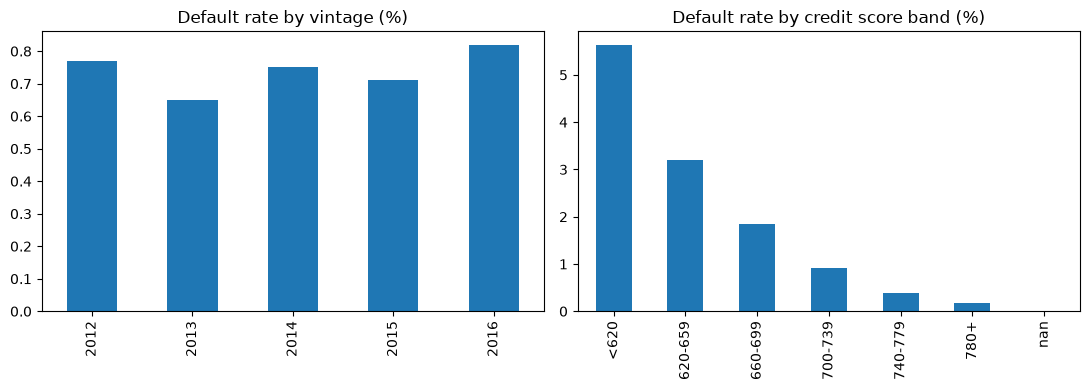

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_vintage["default_rate_%"].plot.bar(ax=axes[0], title="Default rate by vintage (%)")
rate_table(bands, "credit_band")["default_rate_%"].plot.bar(ax=axes[1], title="Default rate by credit score band (%)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(REPORTS / "eda_default_rates.png", dpi=120)
plt.show()

con.close()

## Findings (S4)

All numbers below come from the cells above.

1. **Class balance.** 246,040 loans, 1,821 defaults (0.74%), about 1 default per 135 loans. Accuracy is the wrong metric; S7 uses PR-AUC, ROC-AUC, and KS.
2. **Credit score is the cleanest signal.** Default rate falls at every band, from 5.64% (<620) to 0.18% (780+). The 660-699 band has the most defaults (503), because it has many more loans.
3. **HARP mix shift.** HARP share drops from 35.3% (2012) to 5.1% (2016). The overall rate looks flat (0.77% to 0.82%) while the non-HARP rate rises from 0.23% to 0.77%. The test year has a very different loan mix than the training years.
4. **Missing DTI means HARP.** All 45,481 HARP loans have missing DTI, versus 11 non-HARP loans. Missing DTI defaults at 1.69%, so missingness carries signal and must not be hidden by imputation.
5. **Extreme LTVs are real HARP loans.** LTV reaches 684%, but all 1,850 loans above 150% are HARP. Kept as is; capped for the logistic baseline using a cut-off from training years only.
6. **Confounding through HARP.** No-cash-out refinances look riskiest (0.89%), but drop to 0.33% without HARP loans, the lowest of any purpose.
7. **Disasters drive Florida and 2016.** 103 of Florida's 115 defaults from 2016 loans had a disaster-flagged month in the 24-month window; without them, Florida 2016 falls from 3.86% to 0.40%. About half of all 2016 defaults (215 of 407) were flagged. The non-HARP rate without flagged defaults rises from 0.20% (2012) to 0.41% (2014), then stays flat to slightly lower (0.41%, 0.35%).
8. **Cleaning verified.** No sentinel codes remain; all remaining missing counts outside DTI are 62 or fewer.

**Decisions:** keep the 24-month 90+ label; in S7, report test metrics with and without disaster-flagged defaults (sensitivity check); document the HARP shift and disaster effect in the model card.

**Open questions:** why 10,545 HARP loans have LTV of 60% or less; why the non-HARP rate rose from 2012 to 2014 (untested).